
===== Logistic Regression =====
Accuracy: 0.8009
              precision    recall  f1-score   support

           0       0.81      0.75      0.78       212
           1       0.80      0.84      0.82       245

    accuracy                           0.80       457
   macro avg       0.80      0.80      0.80       457
weighted avg       0.80      0.80      0.80       457

Confusion Matrix:
 [[159  53]
 [ 38 207]]
5‑fold CV AUC: 0.813 ± 0.017

===== KNN =====
Accuracy: 0.7856
              precision    recall  f1-score   support

           0       0.78      0.75      0.77       212
           1       0.79      0.81      0.80       245

    accuracy                           0.79       457
   macro avg       0.78      0.78      0.78       457
weighted avg       0.79      0.79      0.79       457

Confusion Matrix:
 [[160  52]
 [ 46 199]]
5‑fold CV AUC: 0.844 ± 0.021

===== SVM =====
Accuracy: 0.8337
              precision    recall  f1-score   support

           0       0.82      0.

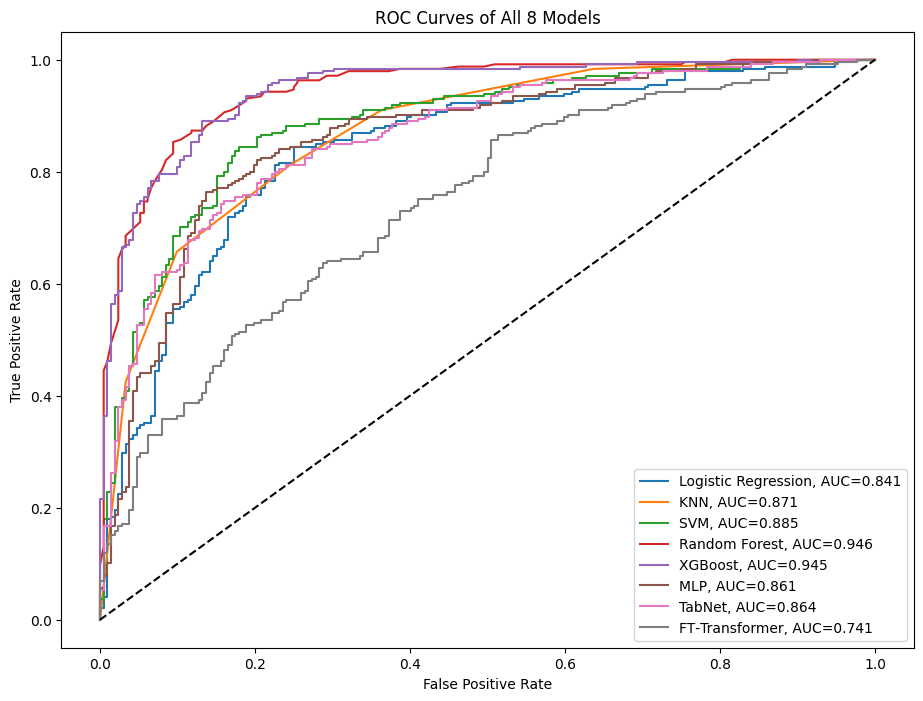


【汇总结果表】
Model                Accuracy   5‑fold CV AUC
--------------------------------------------------
Logistic Regression  0.8009     0.8131 ± 0.0169
KNN                  0.7856     0.8436 ± 0.0207
SVM                  0.8337     0.8631 ± 0.0154
Random Forest        0.8731     0.9328 ± 0.0123
XGBoost              0.8643     0.9268 ± 0.0112
MLP                  0.8031     0.8475 ± 0.0178
TabNet               0.7790     0.8467 ± 0.0207
FT‑Transformer       0.6652     0.7564 ± 0.0306


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings("ignore")

from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, roc_curve, auc

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader

# ===================== 数据加载 & 预处理 =====================
df = pd.read_csv("/kaggle/input/datasets/alifsathar/heart-disease-multi-source-dataset/heart_disease_whole.csv")
df = df.drop("source", axis=1)
df = df.fillna(df.median(numeric_only=True))

X = df.drop("target", axis=1).values
y = df["target"].values

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

class TabDataset(Dataset):
    def __init__(self, data, label):
        self.data = torch.tensor(data, dtype=torch.float32)
        self.label = torch.tensor(label, dtype=torch.float32)
    def __len__(self):
        return len(self.data)
    def __getitem__(self, idx):
        return self.data[idx], self.label[idx]

# ===================== TabNet 轻量化实现 =====================
class TabNetBlock(nn.Module):
    def __init__(self, in_dim, hidden_dim):
        super().__init__()
        self.fc = nn.Sequential(
            nn.Linear(in_dim, hidden_dim),
            nn.BatchNorm1d(hidden_dim),
            nn.ReLU()
        )
        self.attn = nn.Sequential(
            nn.Linear(hidden_dim, in_dim),
            nn.Softmax(dim=1)
        )
    def forward(self, x):
        h = self.fc(x)
        mask = self.attn(h)
        out = x * mask
        return out, mask

class TabNet(nn.Module):
    def __init__(self, n_feature, hidden_dim=32):
        super().__init__()
        self.block1 = TabNetBlock(n_feature, hidden_dim)
        self.block2 = TabNetBlock(n_feature, hidden_dim)
        self.head = nn.Sequential(nn.Linear(n_feature, 1), nn.Sigmoid())
    def forward(self, x):
        x1, _ = self.block1(x)
        x2, _ = self.block2(x1)
        pred = self.head(x2)
        return pred.squeeze()

def train_tabnet(Xtr, ytr, Xva, yva, epochs=100, lr=1e-3):
    ds_tr = TabDataset(Xtr, ytr)
    dl_tr = DataLoader(ds_tr, batch_size=16, shuffle=True)
    model = TabNet(Xtr.shape[1])
    opt = optim.Adam(model.parameters(), lr=lr)
    loss_fn = nn.BCELoss()
    for _ in range(epochs):
        model.train()
        for xb, yb in dl_tr:
            p = model(xb)
            loss = loss_fn(p, yb)
            opt.zero_grad()
            loss.backward()
            opt.step()
    model.eval()
    ds_val = TabDataset(Xva, yva)
    dl_val = DataLoader(ds_val, batch_size=16, shuffle=False)
    ps = []
    with torch.no_grad():
        for xb, _ in dl_val:
            ps.append(model(xb).numpy())
    return np.concatenate(ps)

# ===================== FT‑Transformer 轻量化实现 =====================
class FTBlock(nn.Module):
    def __init__(self, dim, heads, attn_drop=0.1, ff_drop=0.1):
        super().__init__()
        self.norm1 = nn.LayerNorm(dim)
        self.attn = nn.MultiheadAttention(dim, heads, dropout=attn_drop, batch_first=True)
        self.norm2 = nn.LayerNorm(dim)
        self.ffn = nn.Sequential(
            nn.Linear(dim, dim * 4),
            nn.GELU(),
            nn.Dropout(ff_drop),
            nn.Linear(dim * 4, dim),
            nn.Dropout(ff_drop)
        )
    def forward(self, x):
        a, _ = self.attn(self.norm1(x), self.norm1(x), self.norm1(x))
        x = x + a
        x = x + self.ffn(self.norm2(x))
        return x

class FTTransformer(nn.Module):
    def __init__(self, n_feat, dim=32, depth=2, heads=4):
        super().__init__()
        self.tokenizer = nn.Linear(1, dim)
        self.cls = nn.Parameter(torch.randn(1, 1, dim))
        self.blocks = nn.Sequential(*[FTBlock(dim, heads) for _ in range(depth)])
        self.head = nn.Sequential(nn.LayerNorm(dim), nn.Linear(dim, 1))
    def forward(self, x):
        B, F = x.shape
        tokens = self.tokenizer(x.unsqueeze(-1))
        cls_tokens = self.cls.repeat(B, 1, 1)
        seq = torch.cat([cls_tokens, tokens], dim=1)
        seq = self.blocks(seq)
        out = self.head(seq[:, 0, :])
        return torch.sigmoid(out).squeeze()

def train_fttr(Xtr, ytr, Xva, yva, ep=120, lr=1e-3):
    ds_tr = TabDataset(Xtr, ytr)
    dl_tr = DataLoader(ds_tr, batch_size=16, shuffle=True)
    model = FTTransformer(n_feat=Xtr.shape[1], dim=32, depth=2, heads=4)
    opt = optim.Adam(model.parameters(), lr=lr)
    loss_fn = nn.BCELoss()
    for _ in range(ep):
        model.train()
        for xb, yb in dl_tr:
            p = model(xb)
            loss = loss_fn(p, yb)
            opt.zero_grad()
            loss.backward()
            opt.step()
    model.eval()
    ds_val = TabDataset(Xva, yva)
    dl_val = DataLoader(ds_val, batch_size=16, shuffle=False)
    ps = []
    with torch.no_grad():
        for xb, _ in dl_val:
            ps.append(model(xb).numpy())
    return np.concatenate(ps)

# ===================== 传统机器学习模型列表 =====================
ml_models = {
    "Logistic Regression": LogisticRegression(max_iter=500, random_state=42),
    "KNN": KNeighborsClassifier(n_neighbors=5),
    "SVM": SVC(probability=True, random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=42),
    "XGBoost": XGBClassifier(n_estimators=100, random_state=42, eval_metric="logloss"),
    "MLP": MLPClassifier(hidden_layer_sizes=(64,32), max_iter=500, random_state=42)
}

results = {}
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# -------- 跑传统+sklearn‑MLP --------
for name, clf in ml_models.items():
    clf.fit(X_train, y_train)
    y_pred = clf.predict(X_test)
    y_prob = clf.predict_proba(X_test)[:, 1]
    acc = accuracy_score(y_test, y_pred)
    print(f"\n===== {name} =====")
    print(f"Accuracy: {acc:.4f}")
    print(classification_report(y_test, y_pred))
    print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred))

    cv_aucs = []
    for tid, vid in skf.split(X, y):
        Xt, Xv = X[tid], X[vid]
        yt, yv = y[tid], y[vid]
        scv = StandardScaler()
        Xt = scv.fit_transform(Xt)
        Xv = scv.transform(Xv)
        c = clf.__class__(**clf.get_params())
        c.fit(Xt, yt)
        pv = c.predict_proba(Xv)[:,1]
        fpr, tpr, _ = roc_curve(yv, pv)
        cv_aucs.append(auc(fpr, tpr))
    cv_mean = np.mean(cv_aucs)
    cv_std = np.std(cv_aucs)
    print(f"5‑fold CV AUC: {cv_mean:.3f} ± {cv_std:.3f}")

    fpr_test, tpr_test, _ = roc_curve(y_test, y_prob)
    test_auc = auc(fpr_test, tpr_test)
    results[name] = {
        "acc":acc, "cv_mean":cv_mean, "cv_std":cv_std,
        "test_auc":test_auc, "fpr":fpr_test, "tpr":tpr_test
    }

# -------- TabNet --------
print("\n===== TabNet =====")
cv_tab = []
for tid, vid in skf.split(X, y):
    Xt, Xv = X[tid], X[vid]
    yt, yv = y[tid], y[vid]
    scv = StandardScaler()
    Xt = scv.fit_transform(Xt)
    Xv = scv.transform(Xv)
    pv = train_tabnet(Xt, yt, Xv, yv)
    fpr, tpr, _ = roc_curve(yv, pv)
    cv_tab.append(auc(fpr, tpr))
cv_mean_tab = np.mean(cv_tab)
cv_std_tab = np.std(cv_tab)
y_prob_tab = train_tabnet(X_train, y_train, X_test, y_test)
y_pred_tab = (y_prob_tab >= 0.5).astype(int)
acc_tab = accuracy_score(y_test, y_pred_tab)
print(f"Accuracy: {acc_tab:.4f}")
print(classification_report(y_test, y_pred_tab))
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred_tab))
print(f"5‑fold CV AUC: {cv_mean_tab:.3f} ± {cv_std_tab:.3f}")
fpr_tab, tpr_tab, _ = roc_curve(y_test, y_prob_tab)
test_auc_tab = auc(fpr_tab, tpr_tab)
results["TabNet"] = {
    "acc":acc_tab, "cv_mean":cv_mean_tab, "cv_std":cv_std_tab,
    "test_auc":test_auc_tab, "fpr":fpr_tab, "tpr":tpr_tab
}

# -------- FT‑Transformer --------
print("\n===== FT‑Transformer =====")
cv_ft = []
for tid, vid in skf.split(X, y):
    Xt, Xv = X[tid], X[vid]
    yt, yv = y[tid], y[vid]
    scv = StandardScaler()
    Xt = scv.fit_transform(Xt)
    Xv = scv.transform(Xv)
    pv = train_fttr(Xt, yt, Xv, yv)
    fpr, tpr, _ = roc_curve(yv, pv)
    cv_ft.append(auc(fpr, tpr))
cv_mean_ft = np.mean(cv_ft)
cv_std_ft = np.std(cv_ft)
y_prob_ft = train_fttr(X_train, y_train, X_test, y_test)
y_pred_ft = (y_prob_ft >= 0.5).astype(int)
acc_ft = accuracy_score(y_test, y_pred_ft)
print(f"Accuracy: {acc_ft:.4f}")
print(classification_report(y_test, y_pred_ft))
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred_ft))
print(f"5‑fold CV AUC: {cv_mean_ft:.3f} ± {cv_std_ft:.3f}")
fpr_ft, tpr_ft, _ = roc_curve(y_test, y_prob_ft)
test_auc_ft = auc(fpr_ft, tpr_ft)
results["FT‑Transformer"] = {
    "acc":acc_ft, "cv_mean":cv_mean_ft, "cv_std":cv_std_ft,
    "test_auc":test_auc_ft, "fpr":fpr_ft, "tpr":tpr_ft
}

# ===================== 绘制全部ROC曲线 =====================
plt.figure(figsize=(11,8))
color_list = ["#1f77b4","#ff7f0e","#2ca02c","#d62728","#9467bd","#8c564b","#e377c2","#7f7f7f"]
for idx,(name,item) in enumerate(results.items()):
    plt.plot(item["fpr"], item["tpr"], c=color_list[idx], label=f"{name}, AUC={item['test_auc']:.3f}")
plt.plot([0,1],[0,1],"k--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curves of All 8 Models")
plt.legend(loc="lower right")
plt.show()

# ===================== 输出汇总表格文本，方便复制进报告 =====================
print("\n" + "="*70)
print("【汇总结果表】")
print(f"{'Model':<20} {'Accuracy':<10} {'5‑fold CV AUC'}")
print("-"*50)
for name,item in results.items():
    print(f"{name:<20} {item['acc']:<10.4f} {item['cv_mean']:.4f} ± {item['cv_std']:.4f}")
print("="*70)
